# Módulo 4 — Periodograma de Lomb

| | |
|---|---|
| **Responde** | ítems 7a y 7b |
| **Código** | `periodograma_lomb.py` (en esta misma carpeta) |
| **Recibe** | `t_rr` y `rr` (salida del módulo 3) |
| **Devuelve** | `f` (Hz) y `p`, del mismo largo |
| **Responsable** | _completar_ |

> Las funciones se programan en `periodograma_lomb.py`. Este cuaderno sólo las llama, grafica y discute.
> Para guardar una figura para el informe: `graficos.guardar_figura(fig, "nombre")`.
> Para comprobar el módulo: correr `python main.py` desde la carpeta del repo.

In [1]:
# --- Configuración del cuaderno ---

# El cuaderno está en modulos/m4_periodograma_lomb/. Agregando "../.." (la raíz
# del repo) a la ruta de búsqueda, Python encuentra el paquete "modulos".
import sys
sys.path.insert(0, "../..")

# autoreload: si se edita periodograma_lomb.py, los cambios se toman solos al
# correr la próxima celda, sin reiniciar el kernel.
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from modulos.m4_periodograma_lomb import periodograma_lomb as lomb   # nuestro módulo, abreviado "lomb"
from modulos.m0_carga_de_datos import carga_de_datos
from modulos.m0_carga_de_datos.carga_de_datos import Registro
from modulos.m1_acondicionamiento import acondicionamiento as acond
from modulos.m2_pan_tompkins import pan_tompkins
from modulos.herramientas import graficos
from modulos.herramientas.procesamiento_completo import Resultado, procesar_todos

# Mientras lista_de_registros.csv esté vacía, M0 avisa con un warning por cada
# fila. Se silencia sólo ese aviso para que no ensucie la salida.
import warnings
warnings.filterwarnings("ignore", message=".*falta el nombre del archivo.*")

# Tamaño de letra, grilla, etc. iguales en todas las figuras del informe
graficos.aplicar_estilo()

# Parámetros del módulo, para tenerlos a la vista
print("Bandas:", lomb.BANDAS)
print(f"Grilla: de 1/({lomb.SOBREMUESTREO}·T) a {lomb.F_MAX} Hz")
print(f"Atípicos: más de {100*lomb.UMBRAL_ATIPICOS:.0f} % de la mediana de {lomb.VENTANA_ATIPICOS} RR")
print(f"Tendencia: polinomio de grado {lomb.GRADO_TENDENCIA}")

Bandas: {'LF': (0.04, 0.15), 'HF': (0.15, 0.4)}
Grilla: de 1/(4·T) a 0.5 Hz
Atípicos: más de 30 % de la mediana de 11 RR
Tendencia: polinomio de grado 2


## Prueba con un tacograma inventado

Un tacograma de 180 s a 70 lpm cuyo RR oscila un 5 % a 0,2 Hz. El periodograma tiene que mostrar un pico en 0,2 Hz, y el área bajo la curva tiene que ser igual a la varianza del tacograma (así está normalizado `p`).

Se usa `ecg_de_prueba.generar_latidos()` si existe; como ese archivo todavía no está en el repo, si falta se arma el tacograma acá mismo.

Pico en 0.200 Hz (esperado 0,200 Hz)
Área bajo p / varianza = 0.995 (esperado 1)


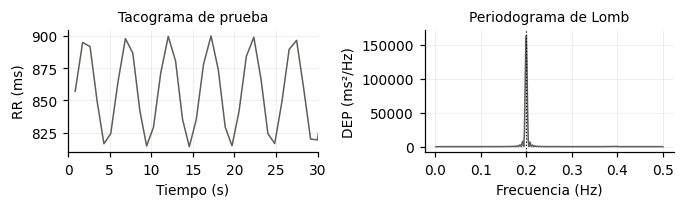

In [2]:
# --- Tacograma de prueba ---
try:
    from modulos.herramientas import ecg_de_prueba
    t_r = ecg_de_prueba.generar_latidos(duracion=180, fc_media=70, amp_mod=0.05, f_mod=0.2)
except ImportError:
    # Cada latido llega un RR después del anterior; el RR oscila ±5 % a 0,2 Hz
    t_r = [0.0]
    while t_r[-1] < 180:
        t_r.append(t_r[-1] + 60/70 * (1 + 0.05 * np.sin(2*np.pi*0.2*t_r[-1])))
    t_r = np.array(t_r)

t_rr_prueba, rr_prueba = t_r[1:], np.diff(t_r)   # el RR se ubica en el latido que lo cierra
f, p = lomb.periodograma_lomb(t_rr_prueba, rr_prueba)

# Comprobaciones: pico en 0,2 Hz y área = varianza (de la serie ya preparada)
_, x = lomb.preparar_tacograma(t_rr_prueba, rr_prueba)
print(f"Pico en {f[np.argmax(p)]:.3f} Hz (esperado 0,200 Hz)")
print(f"Área bajo p / varianza = {np.trapezoid(p, f) / x.var():.3f} (esperado 1)")

fig, axs = plt.subplots(1, 2, figsize=(16/2.54, 5/2.54))
axs[0].plot(t_rr_prueba, 1000*rr_prueba, color=graficos.COLOR_NEUTRO)
axs[0].set(title="Tacograma de prueba", xlabel="Tiempo (s)", ylabel="RR (ms)", xlim=(0, 30))
axs[1].plot(f, p*1e6, color=graficos.COLOR_NEUTRO)
axs[1].axvline(0.2, color="k", ls=":", lw=0.8)
axs[1].set(title="Periodograma de Lomb", xlabel="Frecuencia (Hz)", ylabel="DEP (ms²/Hz)")
fig.tight_layout()

## Tacogramas de los registros

Lo ideal es `procesar_todos(hasta="tacograma")`, que usa M0 → M1 → M2 → M3. Mientras M0 o M3 no estén programados, la celda arma el tacograma acá con un bloque provisorio: lee los CSV con fs = 500 Hz, acondiciona (M1), detecta los picos (M2) y descarta los RR que tocan zonas inválidas (`acond.mascara_valida`). **Cuando M0 y M3 estén listos, esta celda los usa sola y el bloque provisorio deja de correr.**

> OJO: en el bloque provisorio se llama a M2 con `umbral_relativo=0.1`. Con el valor por defecto (0,3), el detector pierde cerca de un tercio de los latidos del registro post ejercicio (se ve en la sección *Controles*, al final).

In [3]:
# --- Tacogramas ---
try:
    resultados = procesar_todos(hasta="tacograma")
except NotImplementedError:
    resultados = []

if not resultados:   # --- provisorio, hasta que M0 y M3 estén listos ---
    FS_PROVISORIA = 500.0     # Hz
    UMBRAL_M2 = 0.1           # ver la nota de arriba
    provisorios = [("ECG_data_pre.csv", "V1", "reposo"),
                   ("ECG_data_post.csv", "V1", "post_ejercicio")]
    for archivo, vol, cond in provisorios:
        ecg = pd.read_csv(carga_de_datos.CARPETA_REGISTROS_CRUDOS / archivo)["Sample"].to_numpy(float)
        reg = Registro(ecg=ecg, fs=FS_PROVISORIA, voluntario=vol, condicion=cond, archivo=archivo, unidades="V")
        res = Resultado(registro=reg)
        res.ecg_acondicionado = acond.acondicionar(reg.ecg, reg.fs)
        res.picos_r = pan_tompkins.detectar_picos_r(res.ecg_acondicionado, reg.fs, UMBRAL_M2)
        # RR en segundos, ubicado en el latido que lo cierra (lo mismo que acordamos para M3).
        # Se descartan los RR con alguno de sus dos latidos en una zona inválida.
        t = res.picos_r / reg.fs
        valida = acond.mascara_valida(reg.ecg, reg.fs)
        ok = valida[res.picos_r[1:]] & valida[res.picos_r[:-1]]
        res.t_rr, res.rr = t[1:][ok], np.diff(t)[ok]
        resultados.append(res)

for res in resultados:
    atipicos = lomb.rr_atipicos(res.rr)
    print(f"{res.registro.nombre:20s} {len(res.rr):4d} RR   {res.t_rr[-1]-res.t_rr[0]:6.1f} s   "
          f"FC media {60/res.rr[~atipicos].mean():5.1f} lpm   atípicos {atipicos.sum()}")

V1_reposo              78 RR     54.8 s   FC media  84.2 lpm   atípicos 0
V1_post_ejercicio     361 RR    171.0 s   FC media 130.9 lpm   atípicos 2


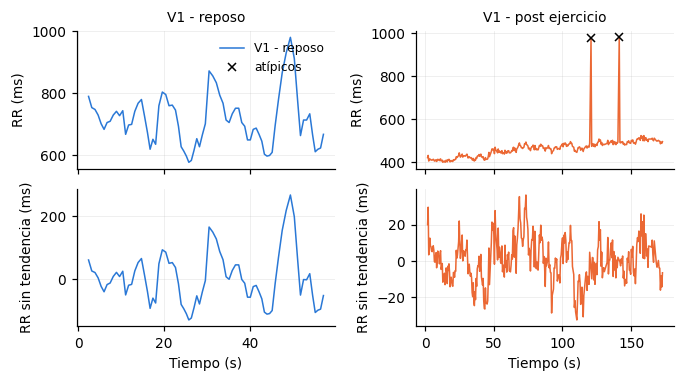

In [4]:
# --- Figura: tacograma y tacograma preparado (lo que entra al periodograma) ---
# Arriba: RR tal como sale de M3, con los atípicos marcados con una cruz.
# Abajo: después de preparar_tacograma(), sin atípicos y sin tendencia.
fig, axs = plt.subplots(2, len(resultados), figsize=(16/2.54, 9/2.54), sharex="col", squeeze=False)
for j, res in enumerate(resultados):
    est = graficos.estilo_registro(res.registro.voluntario, res.registro.condicion)
    atipicos = lomb.rr_atipicos(res.rr)
    axs[0, j].plot(res.t_rr, 1000*res.rr, **est)
    axs[0, j].plot(res.t_rr[atipicos], 1000*res.rr[atipicos], "kx", ms=5, label="atípicos")
    axs[0, j].set(title=est["label"], ylabel="RR (ms)")
    t, x = lomb.preparar_tacograma(res.t_rr, res.rr)
    axs[1, j].plot(t, 1000*x, color=est["color"], ls=est["linestyle"])
    axs[1, j].set(xlabel="Tiempo (s)", ylabel="RR sin tendencia (ms)")
axs[0, 0].legend(loc="upper right")
fig.tight_layout()

## Periodogramas de los registros

PosixPath('/Users/lucasdelia/Desktop/7mo Cuatri ITBA /16.63 - Procesamiento de Señales e Imágenes Biomédicas/Laboratorio/informe/figuras/lomb_periodogramas.pdf')

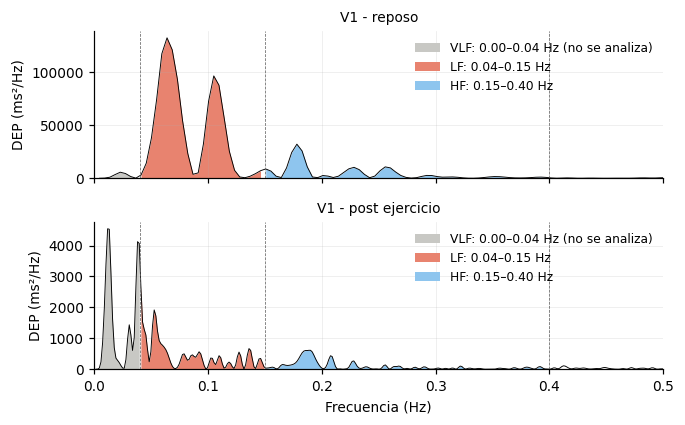

In [5]:
# --- Periodograma de Lomb de cada registro ---
for res in resultados:
    res.f, res.p = lomb.periodograma_lomb(res.t_rr, res.rr)

# Figura del informe (sección 3.4): todos los registros juntos, eje y logarítmico
fig = lomb.figura_periodogramas(resultados)
graficos.guardar_figura(fig, "lomb_periodogramas")

## Ítem 7a — Diferencias entre reposo y actividad física

Bandas de la Task Force (1996): LF de 0,04 a 0,15 Hz y HF de 0,15 a 0,4 Hz. Potencias en ms², unidades normalizadas en % de LF + HF. El pico de HF estima la frecuencia respiratoria (× 60 = respiraciones por minuto).

In [6]:
# --- Tabla: índices espectrales de cada registro completo ---
tabla = pd.DataFrame({res.registro.nombre: {"FC_lpm": 60/res.rr[~lomb.rr_atipicos(res.rr)].mean(),
                                            **lomb.indices_espectrales(res.f, res.p)}
                      for res in resultados}).T
tabla.round(3)

,FC_lpm,LF_ms2,HF_ms2,LF_HF,LFnu_%,HFnu_%,pico_LF_Hz,pico_HF_Hz
V1_reposo,84.236,4870.145,1028.698,4.734,82.561,17.439,0.064,0.178
V1_post_ejercicio,130.879,47.858,21.458,2.230,69.043,30.957,0.041,0.189


El registro post ejercicio no es estacionario: la FC baja durante toda la recuperación. Se lo divide en ventanas de 1 minuto para ver cómo cambia el espectro.

In [7]:
# --- Tabla: post ejercicio minuto a minuto ---
for res in resultados:
    if res.registro.condicion == "post_ejercicio":
        print(res.registro.nombre)
        display(pd.DataFrame(lomb.indices_por_ventanas(res.t_rr, res.rr)).round(3))

V1_post_ejercicio


,inicio_s,n_rr,FC_lpm,LF_ms2,HF_ms2,LF_HF,LFnu_%,HFnu_%,pico_LF_Hz,pico_HF_Hz
0,0.0,140,141.286,55.903,4.215,13.262,92.988,7.012,0.042,0.363
1,60.0,126,127.979,44.249,47.268,0.936,48.351,51.649,0.063,0.185
2,120.0,93,121.162,23.479,15.987,1.469,59.491,40.509,0.044,0.208


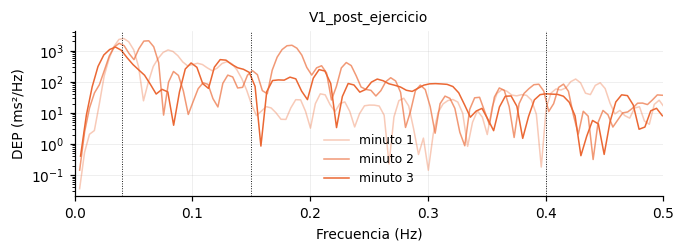

In [8]:
# --- Figura: periodograma de cada minuto del post ejercicio ---
# Más oscuro = más tarde en la recuperación.
post = [res for res in resultados if res.registro.condicion == "post_ejercicio"]
fig, axs = plt.subplots(1, len(post), figsize=(16/2.54, 6/2.54), squeeze=False)
for ax, res in zip(axs[0], post):
    color = graficos.COLOR_CONDICION["post_ejercicio"]
    inicios = np.arange(res.t_rr[0], res.t_rr[-1] - 30, 60)
    for k, t0 in enumerate(inicios):
        sel = (res.t_rr >= t0) & (res.t_rr < t0 + 60)
        f, p = lomb.periodograma_lomb(res.t_rr[sel], res.rr[sel])
        ax.semilogy(f, p*1e6, color=color, alpha=0.35 + 0.65*k/max(len(inicios)-1, 1), label=f"minuto {k+1}")
    for f0, f1 in lomb.BANDAS.values():
        ax.axvline(f0, color="k", ls=":", lw=0.6)
    ax.axvline(lomb.BANDAS["HF"][1], color="k", ls=":", lw=0.6)
    ax.set(title=res.registro.nombre, xlabel="Frecuencia (Hz)", ylabel="DEP (ms²/Hz)", xlim=(0, lomb.F_MAX))
    ax.legend()
fig.tight_layout()

**Qué se ve en V1** (fs = 500 Hz, M2 con umbral 0,1; el texto completo está en la sección 3.4 del informe):

- La potencia cae mucho después del ejercicio: LF de ~4870 a ~48 ms² y HF de ~1030 a ~21 ms², mientras la FC sube de 84 a 131 lpm.
- El reposo tiene picos claros en 0,064 Hz (LF) y 0,18 Hz (HF, unas 11 respiraciones por minuto). El post ejercicio queda casi plano y dos órdenes de magnitud más abajo.
- Minuto a minuto: en el primer minuto la banda HF casi desaparece (LF/HF ≈ 13) y el pico respiratorio se va a 0,36 Hz. En los minutos 2 y 3 la banda HF vuelve (LF/HF entre 0,9 y 1,5), lo que coincide con la reactivación vagal durante la recuperación.
- El LF/HF del reposo (4,7) es poco confiable: el registro dura 55 s y la Task Force pide al menos 2 min para estimar LF.

## Ítem 7b — ¿Sucede de igual manera con ambos voluntarios?

Se registró un solo voluntario, así que no hay comparación entre voluntarios.

## Controles

Cómo cambian los resultados con las decisiones del tratamiento previo. Sirve para justificarlas en el informe.

In [9]:
# --- Control 1: grado del polinomio de tendencia ---
# Con grado 0 sólo se resta la media. En el post ejercicio la tendencia de la
# recuperación agrega potencia en LF si no se la quita.
filas = []
for res in resultados:
    atipicos = lomb.rr_atipicos(res.rr)
    t, rr = res.t_rr[~atipicos], res.rr[~atipicos]
    for grado in range(4):
        x = lomb.quitar_tendencia(t, rr, grado)
        f = lomb.grilla_de_frecuencias(t)
        filas.append({"registro": res.registro.nombre, "grado": grado, **lomb.indices_espectrales(f, lomb.lomb(t, x, f))})
pd.DataFrame(filas).set_index(["registro", "grado"])[["LF_ms2", "HF_ms2", "LF_HF", "LFnu_%"]].round(2)

LF_ms2   HF_ms2  LF_HF  LFnu_%
registro          grado                                 
V1_reposo         0      4879.00  1035.16   4.71   82.50
                  1      4851.97  1025.45   4.73   82.55
                  2      4870.15  1028.70   4.73   82.56
                  3      4786.34   964.42   4.96   83.23
V1_post_ejercicio 0        66.42    42.47   1.56   61.00
                  1        46.43    21.46   2.16   68.39
                  2        47.86    21.46   2.23   69.04
                  3        49.01    21.54   2.28   69.47

In [10]:
# --- Control 2: umbral del detector de M2 ---
# Con el umbral por defecto (0,3) se pierden latidos en el post ejercicio: los RR
# perdidos valen el doble y aparecen como atípicos. Sólo corre con el bloque
# provisorio (necesita reg.ecg y la máscara).
filas = []
for res in resultados:
    reg = res.registro
    valida = acond.mascara_valida(reg.ecg, reg.fs)
    for umbral in (0.3, 0.2, 0.15, 0.1, 0.05):
        picos = pan_tompkins.detectar_picos_r(res.ecg_acondicionado, reg.fs, umbral)
        ok = valida[picos[1:]] & valida[picos[:-1]]
        rr = (np.diff(picos) / reg.fs)[ok]
        filas.append({"registro": reg.nombre, "umbral_M2": umbral, "picos": len(picos), "RR_validos": len(rr),
                      "atipicos": int(lomb.rr_atipicos(rr).sum()), "FC_mediana_lpm": 60/np.median(rr)})
pd.DataFrame(filas).set_index(["registro", "umbral_M2"]).round(1)

picos  RR_validos  atipicos  FC_mediana_lpm
registro          umbral_M2                                             
V1_reposo         0.30          80          78         0            85.0
                  0.20          80          78         0            85.0
                  0.15          80          78         0            85.0
                  0.10          80          78         0            85.0
                  0.05          80          78         0            85.0
V1_post_ejercicio 0.30         253         246        60           125.5
                  0.20         350         339        24           128.8
                  0.15         370         359         6           129.3
                  0.10         375         361         2           129.3
                  0.05         378         359         0           129.3